# [9.2] Truthfulness Directions and Hallucination Probes (solutions)

> **Colab:
> [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter9_alignment_interpretability/exercises/part2_truthfulness_hallucination/9.2_Truthfulness_Directions_and_Hallucination_Probes_exercises.ipynb)
> |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter9_alignment_interpretability/exercises/part2_truthfulness_hallucination/9.2_Truthfulness_Directions_and_Hallucination_Probes_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

# Introduction

“Seven is smaller than three.” The statement is false. Suppose a readout can identify its
falsehood perfectly from an activation. Have we found the component the model uses to answer?
Try a more concrete puzzle: a hidden vector contains both a causal truth coordinate and a spare
copy of the label. A probe can read the spare copy; changing that copy does nothing to the answer.

By the end of this notebook, you will have shown that **perfect decoding can coexist with zero
causal effect** in a fully specified statement-answering organism, using a cross-dataset accuracy
matrix and a matched-strength intervention plot. A shuffled-label direction and a nuisance
direction provide the controls. You will also build an entity-recognition gate to see why
making an unknown entity sound familiar can increase unsupported answers rather than knowledge.

Prerequisites: original ARENA 1.2 (residual streams and hooks), 0.3 (gradient descent), and 9.1
(activation addition). Work entirely in NumPy float64 on CPU. No model, tokenizer or download is
needed. This organism deliberately *constructs* truth and recognition variables. It is not a
claim that an LLM has the same coordinates, knows these facts, or has a universal truth neuron.

The study edition covers truthfulness directions and
hallucination probes through visible implementations and a source-grounded native
bridge. Pretrained cross-dataset extraction, head selection, ITI truthfulness/helpfulness
measurement and real entity-direction interventions are not covered here.

## Content & Learning Objectives

### 1️⃣ Separate truth from topic

Build matched true/false statements and distinguish the labeled proposition from how its
activation was generated. Center all evaluated datasets with the TRAIN mean.

> ##### Learning Objectives
>
> - Define a topic-matched negative and an explicit nuisance variable.
> - Implement mass-mean directions and within-class covariance.

### 2️⃣ Fit and transfer probes

Compare a mean difference, its covariance-adjusted IID readout and a logistic separator.
Evaluate the same fitted vectors on another domain without refitting.

> ##### Learning Objectives
>
> - Derive the logistic gradient and fit a small fixed-budget probe.
> - Measure balanced accuracy and run a label-permutation control.

### 3️⃣ Intervene, then read the answer

Make a prediction before modifying an activation. Keep intervention norm equal across vectors
and measure the downstream answer, rather than the probe's own score.

> ##### Learning Objectives
>
> - Implement normalized activation addition and a stable binary answer probability.
> - Separate a decoding direction from a causally used direction.

### 4️⃣ Recognition is not correctness

A familiarity gate can decide whether to emit an answer without determining whether the answer
is correct. Connect that separation to entity-recognition work and the exact headwise ITI shape.

> ##### Learning Objectives
>
> - Measure coverage, selective correctness, unknown assertions and known refusals separately.
> - Implement scale-normalized shifts on selected attention heads.

### ☆ Bonus

Trace a real research design without treating this constructed organism as its validation.

## Setup code

Use the existing checkout environment. In Jupyter select the repository's Python kernel and
save your exercise copy beside `tests.py`. The setup searches upward for this chapter;
it does not install packages or contact a model service. TRAIN, IID and TRANSFER below are
public constructed teaching roles, not independent evidence about a pretrained model.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

chapter = "chapter9_alignment_interpretability"
section = "part2_truthfulness_hallucination"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).exists())
exercises_dir = root_dir / chapter / "exercises"
section_dir = exercises_dir / section
if str(exercises_dir) not in sys.path:
    sys.path.insert(0, str(exercises_dir))
import part2_truthfulness_hallucination.tests as tests
import part2_truthfulness_hallucination.utils as utils
MAIN = __name__ == "__main__"
np.set_printoptions(precision=4, suppress=True)

# 1️⃣ Separate truth from topic

> ##### Learning Objectives
>
> - Define a topic-matched negative and an explicit nuisance variable.
> - Implement mass-mean directions and within-class covariance.

## A statement is not its surface style

For a true proposition write $s=+1$ and for a false one $s=-1$. Our organism has four
coordinates, $h=(s+f, f, ts, k)$. Here $f$ is an irrelevant surface feature, $t$ controls
whether the spare tag agrees with truth, and $k$ is entity familiarity. The downstream
statement answer uses the fixed margin $m=h_0-h_1-0.8$: it cancels $f$ and ignores the tag
and familiarity. Keeping that causal graph visible prevents a pretty probe from becoming
the explanation by definition.

Each nuisance value appears with both labels and both familiarity values. Such matching
removes a cheap “all true statements discuss topic A” shortcut. A true/false pair about the
same entity is more informative than unrelated true and false sentences. Still, an injected
tag remains a perfect confound in TRAIN. TRANSFER reverses only the tag; the truth variable
and answer mechanism stay fixed. This is a specified domain change, not a new random seed.

The tiny statement table uses arithmetic comparisons so we can check labels independently.
The numeric activation equations are a pedagogical construction attached to those labels,
not activations measured from those English strings. No textual inference is being tested.

In [2]:
statements = [("3 is smaller than 7", 1), ("7 is smaller than 3", 0),
              ("2 is even", 1), ("3 is even", 0)]
for statement, label in statements:
    print(f"{statement:25s} truth={label}")
train_rows, iid_rows, transfer_rows, labels, known = [], [], [], [], []
for sign in (-1., 1.):
    for nuisance, other_nuisance in zip((-1.5, -.5, .5, 1.5), (-1.25, -.25, .25, 1.25)):
        for familiarity in (-1., 1.):
            train_rows.append([sign+nuisance, nuisance, sign, familiarity])
            iid_rows.append([sign+other_nuisance, other_nuisance, sign, familiarity])
            transfer_rows.append([sign+other_nuisance, other_nuisance, -sign, familiarity])
            labels.append(int(sign > 0))
            known.append(familiarity > 0)
X_train, X_iid, X_transfer = map(lambda rows: np.array(rows, dtype=np.float64),
                               (train_rows, iid_rows, transfer_rows))
y = np.array(labels)
known = np.array(known)
print("rows per role:", len(y), "label counts:", np.bincount(y))

3 is smaller than 7       truth=1
7 is smaller than 3       truth=0
2 is even                 truth=1
3 is even                 truth=0
rows per role: 16 label counts: [8 8]


## Reuse the fitted origin

Let TRAIN have shape `(n_train, d)` and the data being evaluated have shape `(n_eval, d)`.
Return the TRAIN mean `(d,)` and `evaluated - train_mean`. Do not compute the evaluated mean:
that would make the transformation depend on the held-out data. Our balanced fixture happens
to have zero mean, so the independent test uses a deliberately shifted evaluated row.

### Exercise - implement `center_from_train`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `center_from_train` with the shapes, equation, edge cases and return contract described above.

In [3]:
def center_from_train(train, evaluated):
    center = np.mean(train, axis=0)
    return center, evaluated - center


tests.test_center_from_train(center_from_train)

All tests in test_center_from_train passed!


<details>
<summary>Hint</summary>

Use `axis=0`. The evaluation array never enters the mean.

</details>

<details>
<summary>Help - what does this check establish?</summary>

A probe includes its preprocessing. A fit that silently changes origins between domains is a different probe.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_center_from_train passed!</pre>

</details>

## A direction from false to true

Marks and Tegmark define the mass-mean direction as $d_{MM}=\mu_+-\mu_-$. Implement that
difference from activations `(n,d)` and labels `(n,)` in `{0,1}`. This is a vector in activation
space, not a calibrated probability and not yet a guarantee of causal use. Preserve its raw
scale here; we will normalize only when comparing interventions.

### Exercise - implement `mass_mean`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `mass_mean` with the shapes, equation, edge cases and return contract described above.

In [4]:
def mass_mean(x, labels):
    return x[labels == 1].mean(axis=0) - x[labels == 0].mean(axis=0)


tests.test_mass_mean(mass_mean)

All tests in test_mass_mean passed!


<details>
<summary>Hint</summary>

Compute one mean per label; subtract false from true.

</details>

<details>
<summary>Help - what does this check establish?</summary>

A sign error makes a truth-to-false intervention look like a failed truth direction.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_mass_mean passed!</pre>

</details>

## Distinguish a feature vector from a decision boundary

A nuisance feature can overlap a truth direction. The covariance of within-class residuals
describes this interference. Subtract each row's own class mean, concatenate the residuals,
then return $C=R^TR/n$ with shape `(d,d)`. Use the declared population denominator `n`, not
`n-1`. This quantity deliberately excludes the separation between class centers.

### Exercise - implement `class_covariance`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `class_covariance` with the shapes, equation, edge cases and return contract described above.

In [5]:
def class_covariance(x, labels):
    residual = x.copy()
    for label in (0, 1):
        mask = labels == label
        residual[mask] -= x[mask].mean(axis=0)
    return residual.T @ residual / len(x)


tests.test_class_covariance(class_covariance)

All tests in test_class_covariance passed!


<details>
<summary>Hint</summary>

Do not call covariance on the uncentered mixture of both labels.

</details>

<details>
<summary>Help - what does this check establish?</summary>

Within-class covariance and total covariance answer different questions. The oracle residuals have identity covariance.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_class_covariance passed!</pre>

</details>

The paper also distinguishes a covariance-adjusted IID readout from the raw feature vector.
For a positive regularizer $\lambda$, solve $(C+\lambda I)w=d_{MM}$. Inputs are `(d,)`,
`(d,d)` and a scalar; return `(d,)`. Our redundant fixture has singular within-class
covariance, so use the visible fixed `0.1` regularizer rather than an unreported inverse or
adaptive tolerance. This is regularized teaching arithmetic, not the paper's exact fitted
configuration. Do not reuse `w` as though it were the same intervention vector as `d_MM`.

### Exercise - implement `iid_direction`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `iid_direction` with the shapes, equation, edge cases and return contract described above.

In [6]:
def iid_direction(direction, covariance, regularizer):
    return np.linalg.solve(covariance + regularizer * np.eye(len(direction)), direction)


tests.test_iid_direction(iid_direction)

All tests in test_iid_direction passed!


<details>
<summary>Hint</summary>

Solve the linear system; matrix multiplication by covariance has the opposite effect.

</details>

<details>
<summary>Help - what does this check establish?</summary>

A decision boundary may undo nuisance interference. That does not establish the physical direction along which a model writes truth.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_iid_direction passed!</pre>

</details>

In [7]:
center, train = center_from_train(X_train, X_train)
_, iid = center_from_train(X_train, X_iid)
_, transfer = center_from_train(X_train, X_transfer)
mm = mass_mean(train, y)
covariance = class_covariance(train, y)
iid_mm = iid_direction(mm, covariance, .1)
print("TRAIN center:", center)
print("mass-mean direction:", mm)
print("within-class diagonal:", np.diag(covariance))

TRAIN center: [0. 0. 0. 0.]
mass-mean direction: [2. 0. 2. 0.]
within-class diagonal: [1.25 1.25 0.   1.  ]


<details><summary>Expected output</summary>

<pre style="font-size: 14px">TRAIN center: [0. 0. 0. 0.]
mass-mean direction: [2. 0. 2. 0.]
within-class diagonal: [1.25 1.25 0.   1.  ]</pre>

</details>

## Summary of 1️⃣

You now have two geometrically different objects: a mean-difference feature candidate and
an interference-adjusted readout. Keep their names separate in the next part.

# 2️⃣ Fit and transfer probes

> ##### Learning Objectives
>
> - Derive the logistic gradient and fit a small fixed-budget probe.
> - Measure balanced accuracy and run a label-permutation control.

## Fit the separator without hiding the objective

For binary labels $y$ and logits $z=Xw$, minimize
$L=\operatorname{mean}[\log(1+e^z)-yz]+\lambda\|w\|^2/2$. There is no bias because we
fixed the origin using TRAIN. The gradient is $X^T(\sigma(z)-y)/n+\lambda w$.
Implement it for `(n,d)`, `(n,)`, `(d,)` and a scalar. The oracle differentiates the loss
numerically coordinate by coordinate, so matching a second handwritten gradient is unnecessary.

### Exercise - implement `logistic_gradient`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `logistic_gradient` with the shapes, equation, edge cases and return contract described above.

In [8]:
def logistic_gradient(x, labels, weights, penalty):
    z = x @ weights
    probabilities = np.exp(-np.logaddexp(0., -z))
    return x.T @ (probabilities - labels) / len(x) + penalty * weights


tests.test_logistic_gradient(logistic_gradient)

All tests in test_logistic_gradient passed!


<details>
<summary>Hint</summary>

A mean loss needs division by number of rows; regularization is not divided by rows again.

</details>

<details>
<summary>Help - what does this check establish?</summary>

A correct gradient checks the stated objective, not the truth of the labels or generalization of the representation.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_logistic_gradient passed!</pre>

</details>

Use fixed-step gradient descent from a zero vector. Return only the fitted weights, and use
no evaluated-domain data for early stopping or hyperparameter selection. The default is
200 steps, learning rate 0.2 and penalty 0.1. This is a tiny numerical probe fit, not training
a language model. Keep its fixed budget visible; changing it in play changes the probe.

### Exercise - implement `fit_logistic`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `fit_logistic` with the shapes, equation, edge cases and return contract described above.

In [9]:
def fit_logistic(x, labels, steps=200, lr=.2, penalty=.1):
    weights = np.zeros(x.shape[1], dtype=np.float64)
    for _ in range(steps):
        weights -= lr * logistic_gradient(x, labels, weights, penalty)
    return weights


tests.test_fit_logistic(fit_logistic)

All tests in test_fit_logistic passed!


<details>
<summary>Hint</summary>

Update a new `(d,)` vector using the gradient you just tested.

</details>

<details>
<summary>Help - what does this check establish?</summary>

Convergence alone does not remove confounds. Even a perfect training separator can exploit the spare tag.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_fit_logistic passed!</pre>

</details>

## Do not let label frequency choose your score

Return $\frac12(\mathrm{TPR}+\mathrm{TNR})$ from predicted labels and true labels `(n,)`.
Both classes are present in these fixtures. Predict true iff the probe logit is **strictly
positive**; a zero logit is assigned false by the declared tie rule. An always-false readout
therefore scores 0.5 even when false statements dominate the dataset.

### Exercise - implement `balanced_accuracy`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `balanced_accuracy` with the shapes, equation, edge cases and return contract described above.

In [10]:
def balanced_accuracy(predicted, labels):
    return .5 * (np.mean(predicted[labels == 1] == 1) + np.mean(predicted[labels == 0] == 0))


tests.test_balanced_accuracy(balanced_accuracy)

All tests in test_balanced_accuracy passed!


<details>
<summary>Hint</summary>

Compute accuracy separately for the positive and negative classes.

</details>

<details>
<summary>Help - what does this check establish?</summary>

Balanced accuracy detects class-collapse controls that ordinary accuracy can make look good.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_balanced_accuracy passed!</pre>

</details>

## Keep the activations, break the label alignment

Return `labels[permutation]` after checking the indices are exactly a permutation of
`range(n)`. Repeated or missing indices must raise `ValueError`. In the main experiment the
fixed permutation interleaves the two original classes, aligning the shuffled labels with
familiarity instead of truth. It preserves label counts and provides an exactly analyzable
negative control. It is one declared control, not a claim about all random permutations.

### Exercise - implement `permute_labels`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `permute_labels` with the shapes, equation, edge cases and return contract described above.

In [11]:
def permute_labels(labels, permutation):
    if not np.array_equal(np.sort(permutation), np.arange(len(labels))):
        raise ValueError("Expected each label index exactly once")
    return labels[permutation]


tests.test_permute_labels(permute_labels)

All tests in test_permute_labels passed!


<details>
<summary>Hint</summary>

Sort the supplied indices to check both coverage and multiplicity.

</details>

<details>
<summary>Help - what does this check establish?</summary>

Shuffling answers without retraining the probe is not the same control as fitting on shuffled labels.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_permute_labels passed!</pre>

</details>

## Evaluate without silently refitting

Inputs are a stacked array of probe weights `(p,d)` and a list of `(activations, labels)`
datasets. Return balanced accuracy `(p, datasets)`, with probes as rows and evaluation domains
as columns. Call the same `balanced_accuracy` you just implemented. Fit no parameters here.
This simple interface makes train/evaluation leakage harder to hide.

### Exercise - implement `transfer_matrix`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `transfer_matrix` with the shapes, equation, edge cases and return contract described above.

In [12]:
def transfer_matrix(probes, datasets):
    return np.array([[balanced_accuracy((x @ w > 0).astype(int), labels)
                      for x, labels in datasets] for w in probes])


tests.test_transfer_matrix(transfer_matrix)

All tests in test_transfer_matrix passed!


<details>
<summary>Hint</summary>

Two loops are fine: their order should match the requested axis labels.

</details>

<details>
<summary>Help - what does this check establish?</summary>

An off-diagonal entry is transfer only when the probe and preprocessing were frozen before that dataset was inspected.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_transfer_matrix passed!</pre>

</details>

In [13]:
lr_weights = fit_logistic(train, y)
permutation = np.array([j for i in range(8) for j in (i, i+8)])
shuffled_y = permute_labels(y, permutation)
shuffled_mm = mass_mean(train, shuffled_y)
tag = np.array([0., 0., 1., 0.])
probe_names = ["mass mean", "IID covariance", "logistic", "spare tag", "shuffled labels"]
probes = np.stack([mm, iid_mm, lr_weights, tag, shuffled_mm])
accuracy = transfer_matrix(probes, [(iid, y), (transfer, y)])
print("Probe                 IID    tag-reversed TRANSFER")
for name, row in zip(probe_names, accuracy):
    print(f"{name:20s} {row[0]:.3f}  {row[1]:.3f}")

Probe                 IID    tag-reversed TRANSFER
mass mean            1.000  0.500
IID covariance       1.000  0.000
logistic             1.000  0.000
spare tag            1.000  0.000
shuffled labels      0.500  0.500


Which vector will be best on the tag-reversed domain? Which vector will change the organism's
answer most per unit norm? Give two forecasts, with confidence and an explanation. They need
not name the same vector. The spare tag predicts TRAIN labels exactly, but the answer margin
does not read coordinate 2. Explain why a probe's training score cannot resolve that tension.

## Summary of 2️⃣

You have implemented an optimization-free probe, a regularized covariance readout and a
logistic fit, with a controlled domain reversal. None of these evaluations has yet changed
the mechanism that generates an answer.

# 3️⃣ Intervene, then read the answer

> ##### Learning Objectives
>
> - Implement normalized activation addition and a stable binary answer probability.
> - Separate a decoding direction from a causally used direction.

## Equal norms make different directions comparable

Implement $h'=h+\alpha d/\|d\|_2$ for activations `(n,d)`, a direction `(d,)` and a scalar
strength. Return a new array; do not mutate the cached clean states. A zero or nonfinite
direction norm must raise `ValueError`. Positive strength points false-to-true only if the
direction sign was calibrated that way. “Normalize every time” is not an excuse to forget
what strength means: it is an activation-space displacement in this constructed organism.

### Exercise - implement `steer`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `steer` with the shapes, equation, edge cases and return contract described above.

In [14]:
def steer(x, direction, alpha):
    norm = np.linalg.norm(direction)
    if not np.isfinite(norm) or norm == 0:
        raise ValueError("Direction must have finite positive norm")
    return x + alpha * direction / norm


tests.test_steer(steer)

All tests in test_steer passed!


<details>
<summary>Hint</summary>

Broadcast a `(d,)` shift across rows, keeping the original array unchanged.

</details>

<details>
<summary>Help - what does this check establish?</summary>

Matched norms rule out a larger raw mean difference as the explanation for a stronger intervention.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_steer passed!</pre>

</details>

## Score the answer, not the probe

Convert an array of binary answer margins to $P(\mathrm{TRUE})=\sigma(m)$ while remaining
finite for logits ±1000. `np.logaddexp` computes $\log(1+e^x)$ stably, so
$\sigma(m)=\exp[-\log(1+e^{-m})]$. The organism's margin is `h[:,0] - h[:,1] - 0.8`;
it is frozen and independent of all fitted probe weights. Measuring the intervened probe
score instead would make every probe look causally successful by construction.

### Exercise - implement `answer_probability`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `answer_probability` with the shapes, equation, edge cases and return contract described above.

In [15]:
def answer_probability(margins):
    return np.exp(-np.logaddexp(0., -margins))


tests.test_answer_probability(answer_probability)

All tests in test_answer_probability passed!


<details>
<summary>Hint</summary>

Avoid directly exponentiating a large positive logit.

</details>

<details>
<summary>Help - what does this check establish?</summary>

A downstream probability change answers a causal question about this organism; a probe-score change answers a geometric question.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_answer_probability passed!</pre>

</details>

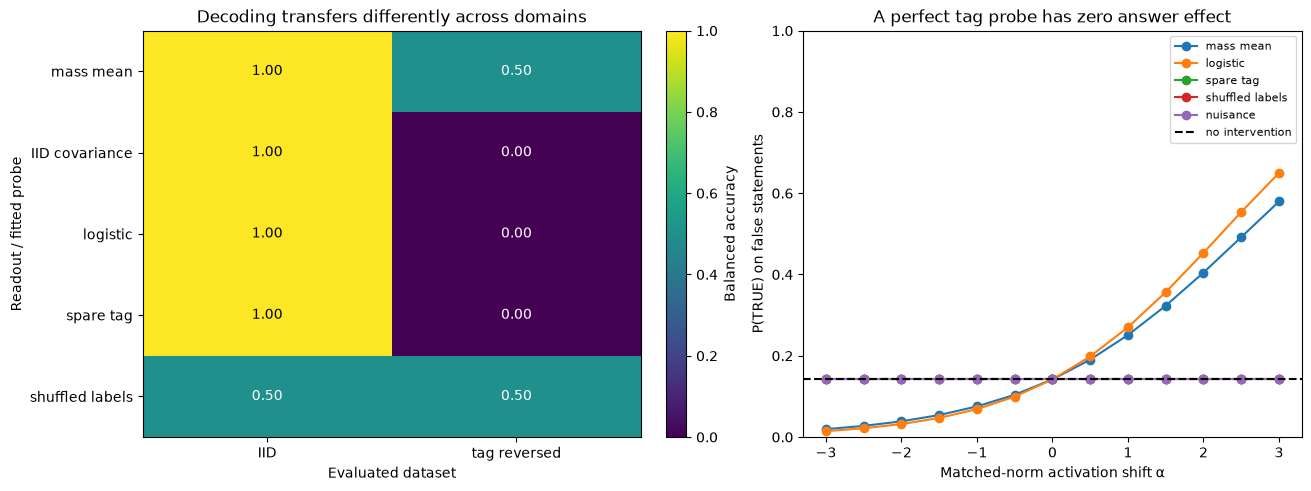

Tag-probe IID accuracy: 1.0
Tag-direction probability range: 0.0


In [16]:
strengths = np.linspace(-3., 3., 13)
false_rows = transfer[y == 0]
nuisance_direction = np.array([1., 1., 0., 0.])
directions = [mm, lr_weights, tag, shuffled_mm, nuisance_direction]
direction_names = ["mass mean", "logistic", "spare tag", "shuffled labels", "nuisance"]
intervention_curves = []
for direction in directions:
    curve = []
    for alpha in strengths:
        changed = steer(false_rows, direction, alpha)
        curve.append(answer_probability(changed[:, 0] - changed[:, 1] - .8).mean())
    intervention_curves.append(curve)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
image = utils.labelled_heatmap(axes[0], accuracy, probe_names, ["IID", "tag reversed"],
                              "Decoding transfers differently across domains")
fig.colorbar(image, ax=axes[0], label="Balanced accuracy")
for name, curve in zip(direction_names, intervention_curves):
    axes[1].plot(strengths, curve, marker="o", label=name)
axes[1].axhline(answer_probability(np.array([-1.8]))[0], color="black", ls="--", label="no intervention")
axes[1].set(xlabel="Matched-norm activation shift α", ylabel="P(TRUE) on false statements",
            title="A perfect tag probe has zero answer effect", ylim=(0, 1))
axes[1].legend(fontsize=8)
plt.show()
print("Tag-probe IID accuracy:", accuracy[3, 0])
print("Tag-direction probability range:", np.ptp(intervention_curves[2]))

## Interpreting the result

The left panel measures decoding; the right panel measures the frozen answer mechanism.
The tag readout has IID accuracy 1.0 and reversed-domain accuracy 0.0, while moving along
that tag changes the answer probability by exactly zero. The shuffled-label direction
reads familiarity, so it also has zero answer effect. The nuisance direction changes both
first coordinates equally and cancels from the answer margin. These failures are useful:
they distinguish information present in a state from a path the answer actually uses.

The mass-mean curve changes despite imperfect transfer. Do not read “more TRUE” as “more
truthful”: we deliberately intervened on *false* statements, making the organism more
confidently wrong. A direction sign must be chosen for the actual task. This experiment
does not reproduce the paper's empirical ranking of probes or ITI's truthfulness gains.

<details><summary>Help - the shuffled probe seems to know something</summary>

It does. It tracks the independent familiarity coordinate. Negative controls need not be
featureless noise; they should fail on the stated truth task. Inspecting what a control
successfully predicts is often more revealing than calling it random.

</details>

<details><summary>Expected output</summary>

<pre style="font-size: 14px">Tag-probe IID accuracy: 1.0
Tag-direction probability range: 0.0</pre>

</details>

## Summary of 3️⃣

A causal direction is defined relative to a mechanism, position and outcome. Decoding a
label, moving a probe score and changing the downstream answer are three separate results.

# 4️⃣ Recognition is not correctness

> ##### Learning Objectives
>
> - Measure coverage, selective correctness, unknown assertions and known refusals separately.
> - Implement scale-normalized shifts on selected attention heads.

## Four denominators for an entity gate

For boolean arrays `(n,)`, return `(coverage, selective_accuracy, unknown_assertion_rate,
known_refusal_rate)`. Coverage divides emitted answers by all rows. Selective accuracy
divides correct emitted answers by emitted rows, returning `np.nan` if none were emitted.
Unknown assertion rate divides emitted unknown answers by unknown entities. Known refusal
rate divides refused known answers by known entities. Both entity classes are present.

This gate is a toy for knowledge awareness, not a hallucination detector. An unsupported
assertion can happen to be true; a refusal can be appropriate. Never merge those categories
into one “truthfulness” score. The known/unknown labels here are declared organism variables,
not a claim about inaccessible knowledge in a real model.

### Exercise - implement `selective_rates`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `selective_rates` with the shapes, equation, edge cases and return contract described above.

In [17]:
def selective_rates(known, emitted, correct):
    coverage = np.mean(emitted)
    selective = np.mean(correct[emitted]) if np.any(emitted) else np.nan
    unknown_assertion = np.mean(emitted[~known])
    known_refusal = np.mean(~emitted[known])
    return np.array([coverage, selective, unknown_assertion, known_refusal])


tests.test_selective_rates(selective_rates)

All tests in test_selective_rates passed!


<details>
<summary>Hint</summary>

Write down the denominator of each rate before indexing.

</details>

<details>
<summary>Help - what does this check establish?</summary>

A system can suppress all outputs and look safe under one metric while having undefined selective accuracy and zero utility.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_selective_rates passed!</pre>

</details>

## Bridge: scale a selected attention-head intervention

ITI shifts a selected set of attention-head activations during inference. Implement the
array operation for `z: (batch, heads, d_head)`, directions `(heads,d_head)`, positive scales
`(heads,)`, a list of selected head indices and strength α. Copy `z`, then add
$\alpha\sigma_jd_j/\|d_j\|$ only at selected heads. Directions in these fixtures are
nonzero. The scales represent projected-activation standard deviations estimated on
TRAIN in a real implementation. This exercise specifies the operation, not how to select
heads from a pretrained model or tune α without contaminating evaluation.

### Exercise - implement `head_shift`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `head_shift` with the shapes, equation, edge cases and return contract described above.

In [18]:
def head_shift(z, directions, scales, selected, alpha):
    result = z.copy()
    for head in selected:
        result[:, head] += alpha * scales[head] * directions[head] / np.linalg.norm(directions[head])
    return result


tests.test_head_shift(head_shift)

All tests in test_head_shift passed!


<details>
<summary>Hint</summary>

The selected-head axis is the middle axis; preserve the batch and final dimension.

</details>

<details>
<summary>Help - what does this check establish?</summary>

Residual-stream addition and selected pre-output attention-head addition have different hook locations and cannot be silently interchanged.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_head_shift passed!</pre>

</details>

In [19]:
print("Recognition shift   coverage  selective-acc  unknown-assert  known-refusal")
correct = known.copy()  # Declared: this organism recalls only known entity answers.
for alpha in (-2., 0., 2.):
    emitted = answer_probability(transfer[:, 3] + alpha) > .5
    rates = selective_rates(known, emitted, correct)
    print(f"{alpha:17.1f}   " + "  ".join(f"{rate:.3f}" for rate in rates))

Recognition shift   coverage  selective-acc  unknown-assert  known-refusal
             -2.0   0.000  nan  0.000  1.000
              0.0   0.500  1.000  0.000  0.000
              2.0   1.000  0.500  1.000  0.000


<details><summary>Expected output</summary>

At shift -2, all answers are refused: coverage 0, selective accuracy undefined, unknown
assertions 0, known refusals 1. At zero, coverage is 0.5 and selective accuracy is 1. At +2,
coverage becomes 1 and selective accuracy falls to 0.5 because every unknown entity now
receives an answer. The truth-readout parameters and stored facts never changed.

</details>

## Try it yourself

Forecast before running: reverse the organism's downstream truth readout while keeping the
probe training activations fixed. Will a positive mass-mean shift still increase P(TRUE)?
This changes the causal mechanism, not just a seed. Change `readout_sign` below from +1 to -1,
explain the sign of the curve, and inspect the spare-tag control alongside it. Then change
only `tag_weight`: when does a previously noncausal probe become causally relevant?

In [20]:
readout_sign = 1.0
tag_weight = 0.0
play_alphas = np.array([-2., 0., 2.])
for name, direction in (("mass mean", mm), ("spare tag", tag)):
    probabilities = []
    for alpha in play_alphas:
        changed = steer(transfer[y == 0], direction, alpha)
        margin = readout_sign * (changed[:, 0] - changed[:, 1]) + tag_weight * changed[:, 2] - .8
        probabilities.append(answer_probability(margin).mean())
    print(name, np.round(probabilities, 4))

mass mean [0.0386 0.1419 0.4047]
spare tag [0.1419 0.1419 0.1419]


## A native experiment you can now specify

For a future LLM study, freeze exact checkpoints/tokenizers, prompts and entity identities;
split by dataset/entity before fitting; record the residual layer/token or attention-head
hook; estimate means, scales and any centering on TRAIN only. Evaluate frozen probes on
topic-matched true/false pairs and held-out datasets, including negations and label shuffles.
For causality, modify the activation at the declared site and score the *model's* answers,
plus fluency/helpfulness and task side effects. Keep probe selection and steering-strength
selection out of the final evaluated domain. Entity familiarity is not general self-knowledge.

## Limitations

All representations here were constructed from known labels. They demonstrate identifiable
failure modes and exact causal arithmetic, not truth representations learned from text.
There is no released-model activation extraction, native ITI run, language-generation
truthfulness rubric or entity-recognition SAE fit.

## Summary of 4️⃣

Recognition, correctness and willingness to answer must be measured separately. A steering
operation can change willingness without adding the fact that an answer would require.

# ☆ Bonus

## Anomaly hunt and further reading

Why can a covariance-adjusted separator transfer better in one domain yet be a weaker
activation-writing direction? Decompose each vector into the truth, nuisance and tag axes.
Try an invertible change of coordinates and transform the readout consistently: which
quantities are coordinate-dependent, and which downstream intervention predictions survive?

- [Marks & Tegmark, The Geometry of Truth](https://arxiv.org/abs/2310.06824): mass-mean
  directions, their IID covariance-adjusted readouts, dataset transfer and causal tests.
- [Li et al., Inference-Time Intervention](https://arxiv.org/abs/2306.03341): selected
  attention-head shifts and the truthfulness/helpfulness tradeoff.
- [Ferrando et al., Do I Know This Entity?](https://arxiv.org/abs/2411.14257): entity-recognition
  directions and knowledge-awareness interventions, with SAE discovery in real models.

The publications motivate the distinctions, not the numerical outcomes of this fixture.